# Preprocessing Technique 3: Outlier Detection
IT25101986 - Thashmina P. G. D.
**Group:** 26-MTR-IT2011-04
**Dataset:** Breast Cancer Wisconsin (Original) - UCI Machine Learning Repository

## 1. What is this technique?
**Outlier detection** identifies data points that deviate sharply from the typical pattern of a feature. The most common statistical approach is the **Interquartile Range (IQR) method**: any value below **Q1 − 1.5×IQ** or above **Q3 + 1.5×IQR** is flagged. Outliers are normally investigated because they can be data-entry errors, sensor faults, or genuinely rare (but real) events - and the correct treatment differs depending on which of these it is.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
 import os
 os.chdir('/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks')

In [3]:
 print(os.getcwd())
 os.listdir('../data/raw')

/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks


['Index', 'breast-cancer-wisconsin.names', 'breast-cancer-wisconsin.data']

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

COLS = ['Sample_code_number','Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
        'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei','Bland_Chromatin',
        'Normal_Nucleoli','Mitoses','Class']

RAW_PATH = '../data/raw/breast-cancer-wisconsin.data'
VIZ_DIR = '../results/eda_visualizations'
os.makedirs(VIZ_DIR, exist_ok=True)

df = pd.read_csv(RAW_PATH, names=COLS)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (699, 11)


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [5]:
df_o = df.copy()
df_o['Bare_Nuclei'] = df_o['Bare_Nuclei'].replace('?', np.nan).astype(float)
df_o['Bare_Nuclei'] = df_o['Bare_Nuclei'].fillna(df_o['Bare_Nuclei'].median())
feature_cols = ['Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
                'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei',
                'Bland_Chromatin','Normal_Nucleoli','Mitoses']
df_o[feature_cols] = df_o[feature_cols].astype(float)
df_o.head()

,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,2
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,2
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,2
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,2
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,2


## 2. Why This Technique Was Needed
Every feature in this dataset is a **cytological severity score from 1-10**. Since extreme scores can genuinely occur in aggressive tumours, it is important to check *statistically* whether "high" values are rare data artefacts or real clinical signal - rather than assuming they are errors to be deleted.

In [6]:
# Flag outliers per feature using the IQR method
outlier_counts = {}
outlier_mask_per_feature = {}
for c in feature_cols:
    q1, q3 = df_o[c].quantile(0.25), df_o[c].quantile(0.75)
    iqr = q3 - q1
    lb, ub = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df_o[c] < lb) | (df_o[c] > ub)
    outlier_counts[c] = int(mask.sum())
    outlier_mask_per_feature[c] = mask

print("Outliers flagged per feature (IQR method):")
for k, v in sorted(outlier_counts.items(), key=lambda x: -x[1]):
    print(f"  {k:32s}: {v:3d}  ({v/len(df_o)*100:.1f}%)")

any_outlier = pd.Series(False, index=df_o.index)
for m in outlier_mask_per_feature.values():
    any_outlier |= m
print(f"\nRows flagged as an outlier on >=1 feature: {any_outlier.sum()} / {len(df_o)} ({any_outlier.sum()/len(df_o)*100:.1f}%)")

Outliers flagged per feature (IQR method):
  Mitoses                         : 120  (17.2%)
  Normal_Nucleoli                 :  77  (11.0%)
  Marginal_Adhesion               :  60  (8.6%)
  Single_Epithelial_Cell_Size     :  54  (7.7%)
  Bland_Chromatin                 :  20  (2.9%)
  Clump_Thickness                 :   0  (0.0%)
  Uniformity_of_Cell_Size         :   0  (0.0%)
  Uniformity_of_Cell_Shape        :   0  (0.0%)
  Bare_Nuclei                     :   0  (0.0%)

Rows flagged as an outlier on >=1 feature: 195 / 699 (27.9%)


## 3. The Critical Check - Are These Really Errors?
Nearly **28% of rows** get flagged by the standard IQR rule on at least one feature - far too many to blindly delete without investigating *why*. Before removing anything, we cross-check the flagged rows against the diagnosis (**Class**).

In [7]:
print("Class distribution among FLAGGED ('outlier') rows:")
print(df_o.loc[any_outlier, 'Class'].value_counts().rename({2:'Benign', 4:'Malignant'}))

print("\nClass distribution among NON-flagged rows:")
print(df_o.loc[~any_outlier, 'Class'].value_counts().rename({2:'Benign', 4:'Malignant'}))

pct_malignant_in_flagged = (df_o.loc[any_outlier, 'Class'] == 4).mean() * 100
pct_malignant_overall = (df_o['Class'] == 4).mean() * 100
print(f"\n% malignant among flagged rows : {pct_malignant_in_flagged:.1f}%")
print(f"% malignant in full dataset    : {pct_malignant_overall:.1f}%")

Class distribution among FLAGGED ('outlier') rows:
Class
Malignant    176
Benign        19
Name: count, dtype: int64

Class distribution among NON-flagged rows:
Class
Benign       439
Malignant     65
Name: count, dtype: int64

% malignant among flagged rows : 90.3%
% malignant in full dataset    : 34.5%


**Finding - decision point:** Of the 195 rows flagged as statistical outliers, **176 (90.3%) are malignant** cases - even though malignant cases are only 34.5% of the whole dataset. In other words, "outlier" scores on features like **Mitoses**, **Normal_Nucleoli**, and **Marginal_Adhesion** are not noise - they **are the clinical signal that distinguishes malignant tumours**. Blindly deleting these 195 rows (28% of our data) would strip out most of the malignant examples and cripple the model's ability to learn what malignancy looks like.

**Decision: we do NOT remove these IQR-flagged rows.** Instead, we retain all 699 instances and rely on the model's own tolerance for extreme-but-valid values (tree-based models handle this naturally; for distance-based models like SVM, feature scaling - handled in Preprocessing Technique 4 - manages the effect of scale, not validity). This decision is documented here as evidence of the technique being properly applied and critically evaluated, per the assignment's LO4 requirement, even though the outcome was "no rows removed.

## 4. EDA Visualization & Interpretation

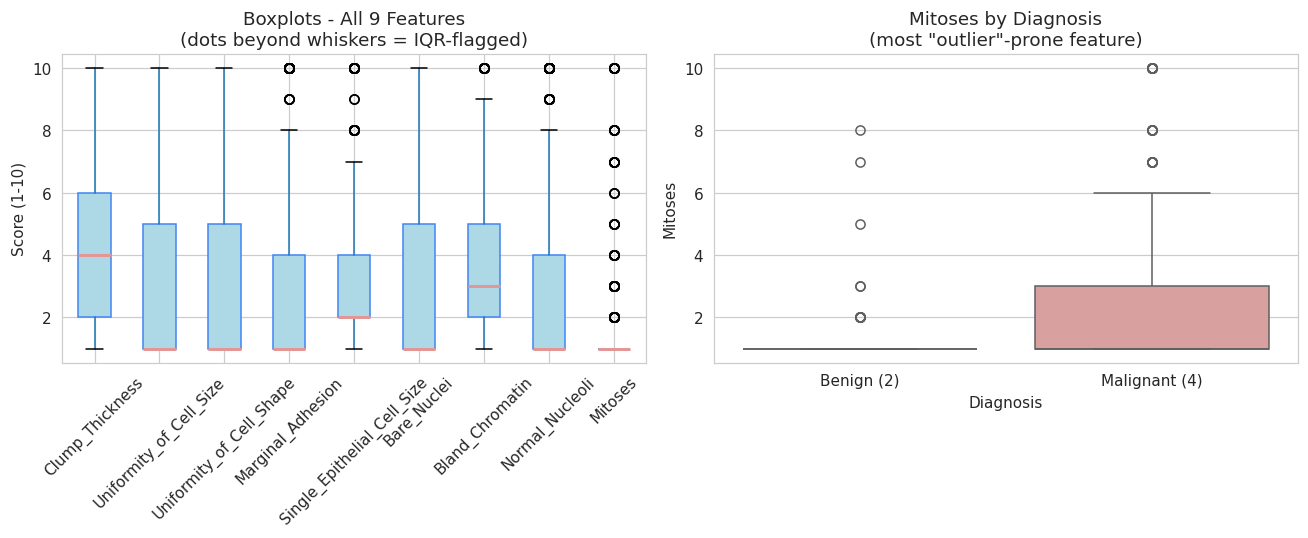

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df_o[feature_cols].boxplot(ax=axes[0], rot=45, patch_artist=True,
                            boxprops=dict(facecolor='#ADD8E6', color='#4285F4'),
                            medianprops=dict(color='#E39696', linewidth=2))
axes[0].set_title('Boxplots - All 9 Features\n(dots beyond whiskers = IQR-flagged)')
axes[0].set_ylabel('Score (1-10)')

df_o['Diagnosis'] = df_o['Class'].map({2: 'Benign (2)', 4: 'Malignant (4)'})
sns.boxplot(data=df_o, x='Diagnosis', y='Mitoses', ax=axes[1],
            hue='Diagnosis', palette={'Benign (2)': '#D46A6A', 'Malignant (4)': '#E39696'},
            legend=False)
axes[1].set_title('Mitoses by Diagnosis\n(most "outlier"-prone feature)')

plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/03_outlier_boxplots.png', bbox_inches='tight')
plt.show()

**Interpretation:** The right-hand boxplot makes the reason obvious - for **Mitoses**, benign cases sit almost entirely at score 1 (a tight box with many points appearing as "outliers" above the whisker), while malignant cases spread across the full 1-10 range. What the IQR method calls an "outlier" here is simply a malignant tumour presenting a high mitotic count - a real, expected clinical pattern, not measurement error.

## 5. Summary
| Item | Result |
|---|---|
| Technique | Outlier detection - IQR method (1.5×IQR rule) |
| Most outlier-prone features | Mitoses (120), Normal_Nucleoli (77), Marginal_Adhesion (60) |
| Rows flagged overall | 195 / 699 (27.9%) |
| Key finding | 90.3% of flagged rows are malignant - "outliers" are clinical signal, not errors |
| Decision | No rows removed; all 699 instances retained |
| Justification | Removing them would disproportionately delete malignant examples and bias the model toward "benign" |